# 06 : Ensemble and model outside the course (Step 3, part 2)
Owner (module 3): Antonin Charron. Implemented by Enki Millet with Claude Code (`ai_governance/PROMPT_LOG.md`, P4). Versions of our AutoML pipeline:
* **v0.1** (notebook 02): standard models, the logistic regression baseline is the best;
* **v0.2** (notebook 03): tuned random forest and LightGBM;
* **v0.3** (this notebook): an **ensemble** that combines several algorithms (stacking, soft voting);
* **v0.4** (this notebook): a model **outside the course**, a multilayer perceptron (neural network).

Same protocol as notebooks 02 and 03: only `dataset/train.csv`, the same 5 stratified folds (`cv_folds()`), the
same score (PR-AUC), the preprocessing inside each pipeline, train score vs CV score to see overfitting.
The test set is only used in notebook 04. The model kept for each version is chosen here, on the CV scores.

## 1. Limitations of the last versions
**v0.1 (standard models).** All the models stay at CV PR-AUC 0.43-0.45: linear models cannot use the
interactions (month × economy, previous contact × economy), and a single tree overfits quickly.

**v0.2 (random forest, LightGBM).** They break this ceiling (CV 0.465 and 0.467, significant on the test set,
notebook 04), but:
* **they do not survive the drift:** trained on the oldest 80 % of calls and tested on the most recent 20 %, their
  ROC-AUC falls to 0.68, below the logistic regression (0.75), because trees cannot extrapolate `euribor3m`;
* **the random forest probabilities are not real probabilities** (`class_weight="balanced_subsample"` pushes them
  up), and LightGBM underestimates the yes after the drift (8.7 % predicted for 30.8 % real);
* the two models make similar errors (both are made of trees), so choosing one or the other changes little.

**What we try next.**
* v0.3: combine a linear model and the two tree models. The linear model ranks differently from the trees, so a
  combination may keep the ranking of the trees and some of the robustness of the linear model.
* v0.4: a neural network, a different family of model. Its function is smooth (no leaves), so it may extrapolate
  better than trees on the temporal split.

In [1]:
import sys, time, warnings
from pathlib import Path
sys.path.append(str(Path("..") / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import RandomizedSearchCV, cross_validate
from scipy.stats import loguniform

from common import *
from evaluation import SCORING, cv_summary
from models import BUILDERS, ENSEMBLE_BASE, get_model, save_best_params
warnings.filterwarnings("ignore")
pd.set_option("display.precision", 4)
set_seed()

train, test = random_split()
X_train, y_train = xy(train)
assert len(X_train) == 32940, "train.csv is not complete: run code/step2_split.py again"
cv = cv_folds()
print("train:", X_train.shape, " share of yes: %.4f" % y_train.mean())

train: (32940, 20)  share of yes: 0.1127


In [2]:
rows = []

def evaluate(name, model):
    # 5-fold CV: mean and std of the validation scores + score on the training folds (same as notebook 03)
    s = cross_validate(model, X_train, y_train, cv=cv, scoring=SCORING, return_train_score=True, n_jobs=-1)
    row = cv_summary(s, name)
    row["gap_train_cv"] = row["train_pr_auc_mean"] - row["cv_pr_auc_mean"]
    return row

# references: the baseline and the two v0.2 models, with their tuned parameters
for n in ENSEMBLE_BASE:
    rows.append(evaluate(n, get_model(n)))
pd.DataFrame(rows)

,model,cv_pr_auc_mean,cv_pr_auc_std,cv_roc_auc_mean,cv_roc_auc_std,train_pr_auc_mean,train_pr_auc_std,fit_time_s,gap_train_cv
0,logreg_baseline,0.4484,0.0056,0.7886,0.0108,0.4558,0.0017,0.1972,0.0073
1,random_forest,0.4653,0.0038,0.7987,0.0065,0.5717,0.0021,1.1642,0.1064
2,lightgbm,0.4673,0.0089,0.8002,0.0063,0.5037,0.0018,0.3009,0.0364


## 2. v0.3: ensemble learning
### 2.1 The two methods
* **Soft voting:** the score of a client is the mean of the probabilities given by the logistic regression, the
  random forest and LightGBM. Nothing more is learned.
* **Stacking** (*stacked generalization*, Wolpert 1992): a second model, the **meta-model** (here a logistic
  regression), learns how much to trust each base model. Its inputs are the 3 scores of the base models, its
  target is `y`. The important point is which scores it learns on: if the base models score rows they were
  trained on, the random forest looks almost perfect (train PR-AUC 0.57 against 0.47 in CV) and the meta-model
  would trust it too much. So `StackingClassifier(cv=cv_folds())` gives the meta-model **out-of-fold** scores: the
  same mechanism as the threshold choice in notebook 04. Then the base models are refitted on all the rows.

Reference: D. H. Wolpert (1992), *Stacked generalization*, Neural Networks 5(2), 241-259.

The scale of the scores does not matter for stacking (the meta-model learns one weight per model), but it does for
voting: the random forest probabilities are pushed up by its class weights, so it weighs more in the mean.

In [3]:
t0 = time.time()
rows.append(evaluate("soft_voting", BUILDERS["soft_voting"]()))
print("voting: %.0f s" % (time.time() - t0)); t0 = time.time()
rows.append(evaluate("stacking", BUILDERS["stacking"]()))
print("stacking: %.0f s" % (time.time() - t0))
pd.DataFrame(rows).set_index("model")

voting: 3 s


stacking: 15 s


,cv_pr_auc_mean,cv_pr_auc_std,cv_roc_auc_mean,cv_roc_auc_std,train_pr_auc_mean,train_pr_auc_std,fit_time_s,gap_train_cv
model,,,,,,,,
logreg_baseline,0.4484,0.0056,0.7886,0.0108,0.4558,0.0017,0.1972,0.0073
random_forest,0.4653,0.0038,0.7987,0.0065,0.5717,0.0021,1.1642,0.1064
lightgbm,0.4673,0.0089,0.8002,0.0063,0.5037,0.0018,0.3009,0.0364
soft_voting,0.4679,0.0047,0.8000,0.0069,0.5202,0.0011,2.2996,0.0523
stacking,0.4701,0.0038,0.8000,0.0064,0.5437,0.0014,14.1094,0.0736


In [4]:
# weights learned by the meta-model of the stacking (fitted once on the whole train set, for reading only)
stack = BUILDERS["stacking"]().fit(X_train, y_train)
meta = stack.final_estimator_
# with 2 classes, StackingClassifier keeps one column per base model: P(yes)
pd.DataFrame({"base model": ENSEMBLE_BASE, "weight in the meta-model": meta.coef_[0]}).round(3)

,base model,weight in the meta-model
0,logreg_baseline,0.699
1,random_forest,3.484
2,lightgbm,1.637


### 2.2 What we learn
* **Both ensembles reach the level of the best v0.2 model:** stacking 0.470 (+0.022 over the baseline), soft voting
  0.468, against 0.467 for LightGBM alone and 0.465 for the random forest.
* **But the ensemble does not clearly beat its best member:** stacking minus LightGBM = +0.003, smaller than the std
  between folds (0.004 to 0.009). The base models make similar errors: the random forest and LightGBM are both made
  of trees and use the same variables, and the logistic regression is weaker. An ensemble helps when its members
  are good *and* different.
* **Weights of the meta-model:** random forest 3.48, LightGBM 1.64, logistic regression 0.70. The linear model gets
  the smallest weight, so it adds little to the trees. (These weights are not a strict importance ranking: the
  three probabilities do not have the same scale, the random forest ones are pushed up by its class weights.)
* **Overfitting:** stacking train 0.544 vs CV 0.470 (gap 0.07), between LightGBM (0.04) and the random forest
  (0.11). The out-of-fold scores of the meta-model work: the gap is not larger than the one of its members.
* **Cost:** about 14 s per fit against 0.3 s for LightGBM (5 inner folds × 3 models + a final refit).

The stacking is the best ensemble in CV, so it is the one evaluated on the test set in notebook 04.

## 3. v0.4: a model outside the course, the multilayer perceptron
### 3.1 The algorithm
A multilayer perceptron (MLP) is a feed-forward neural network. Each hidden neuron computes a weighted sum of its
inputs and applies the ReLU function `max(0, z)`; the output neuron applies a sigmoid and gives P(yes), like a
logistic regression. With no hidden layer it **is** a logistic regression: the hidden layers let it learn
non-linear combinations of the variables (for example "previous contact AND low interest rate"). The weights are
learned by back-propagation with the Adam optimiser, minimising the log-loss (the same loss as the logistic
regression), with an L2 penalty `alpha` (the same role as `1/C`).

Inputs: the same preprocessor as the other models (one-hot encoding and **standardisation**, which a neural network
needs: the course lists neural networks among the models that need scaling).

### 3.2 Why this model (references)
* **Moro, Cortez and Rita (2014)**, *A data-driven approach to predict the success of bank telemarketing*, Decision
  Support Systems 62, 22-31: the reference paper of this dataset compared logistic regression, decision trees, SVM
  and a neural network, and **the neural network was the best** (AUC ≈ 0.8). It is the natural candidate.
* **Kadra, Lindauer, Hutter and Grabocka (2021)**, *Well-tuned simple nets excel on tabular datasets*, NeurIPS 34:
  a simple MLP can compete with gradient boosting on tabular data **if its regularisation is tuned**. So we tune
  `alpha`, the size of the network and the number of epochs.
* **Grinsztajn, Oyallon and Varoquaux (2022)**, *Why do tree-based models still outperform deep learning on typical
  tabular data?*, NeurIPS 35 (Datasets and Benchmarks): on medium-size tabular data (about 10,000 rows) the trees
  usually stay better, because neural networks learn smooth functions and are hurt by uninformative features. So
  we do **not** expect the MLP to beat LightGBM on the random split; the question is whether its smooth function
  extrapolates better after the drift (notebook 04, temporal split).

### 3.3 Choices
* `early_stopping=False`: in scikit-learn, early stopping keeps the epoch with the best **accuracy** on an internal
  validation split. With 11 % of yes the accuracy is almost flat (predicting "no" for everybody already gives
  0.887), so it would stop at a random epoch. Instead the number of epochs (`max_iter`) is a hyperparameter,
  chosen with the 5 folds and the PR-AUC like the others.
* No class weights (the MLP of scikit-learn has none): the probabilities stay close to real probabilities.

In [5]:
rows.append(evaluate("mlp (default)", BUILDERS["mlp"]()))
pd.DataFrame(rows).set_index("model")

,cv_pr_auc_mean,cv_pr_auc_std,cv_roc_auc_mean,cv_roc_auc_std,train_pr_auc_mean,train_pr_auc_std,fit_time_s,gap_train_cv
model,,,,,,,,
logreg_baseline,0.4484,0.0056,0.7886,0.0108,0.4558,0.0017,0.1972,0.0073
random_forest,0.4653,0.0038,0.7987,0.0065,0.5717,0.0021,1.1642,0.1064
lightgbm,0.4673,0.0089,0.8002,0.0063,0.5037,0.0018,0.3009,0.0364
soft_voting,0.4679,0.0047,0.8000,0.0069,0.5202,0.0011,2.2996,0.0523
stacking,0.4701,0.0038,0.8000,0.0064,0.5437,0.0014,14.1094,0.0736
mlp (default),0.3676,0.0101,0.7341,0.0080,0.7410,0.0070,8.2953,0.3734


In [6]:
mlp_space = {
    "model__hidden_layer_sizes": [(16,), (32,), (64,), (32, 16), (64, 32), (128, 64)],
    "model__alpha": loguniform(1e-5, 1.0),               # L2 penalty
    "model__learning_rate_init": loguniform(1e-4, 1e-2),
    "model__batch_size": [128, 256, 512],
    "model__max_iter": [10, 20, 40, 80, 150],            # number of epochs (no early stopping, see above)
}
t0 = time.time()
mlp_search = RandomizedSearchCV(BUILDERS["mlp"](), mlp_space, n_iter=20, cv=cv, scoring=SCORING, refit=False,
                                return_train_score=True, random_state=SEED, n_jobs=-1)
mlp_search.fit(X_train, y_train)
res = pd.DataFrame(mlp_search.cv_results_)
best = res.loc[res["mean_test_pr_auc"].idxmax()]
mlp_params = {k: (v.item() if hasattr(v, "item") else v) for k, v in best["params"].items()}
mlp_params["model__hidden_layer_sizes"] = list(mlp_params["model__hidden_layer_sizes"])
save_best_params("mlp", mlp_params)
print("search time: %.0f s" % (time.time() - t0))
print("best CV PR-AUC: %.4f" % best["mean_test_pr_auc"])
mlp_params

search time: 33 s
best CV PR-AUC: 0.4529


{'model__alpha': 0.010129197956845729,
 'model__batch_size': 512,
 'model__hidden_layer_sizes': [128, 64],
 'model__learning_rate_init': 0.00012966511753760416,
 'model__max_iter': 80}

In [7]:
cols = ["param_model__hidden_layer_sizes", "param_model__alpha", "param_model__learning_rate_init",
        "param_model__batch_size", "param_model__max_iter", "mean_train_pr_auc", "mean_test_pr_auc", "std_test_pr_auc"]
res.sort_values("mean_test_pr_auc", ascending=False)[cols].head(6)

,param_model__hidden_layer_sizes,param_model__alpha,param_model__learning_rate_init,param_model__batch_size,param_model__max_iter,mean_train_pr_auc,mean_test_pr_auc,std_test_pr_auc
2,"(128, 64)",1.0129e-02,0.0001,512,80,0.5345,0.4529,0.0076
3,"(32, 16)",4.9291e-01,0.0002,256,80,0.4783,0.4528,0.0089
12,"(128, 64)",9.4570e-04,0.0002,256,10,0.4856,0.4526,0.0052
16,"(64,)",7.2648e-02,0.0002,512,40,0.4764,0.4503,0.0047
10,"(32, 16)",3.5205e-01,0.0004,256,20,0.4706,0.4497,0.0085
18,"(16,)",3.7962e-05,0.0018,512,20,0.4835,0.4494,0.0063


In [8]:
rows.append(evaluate("mlp (tuned)", get_model("mlp")))
pd.DataFrame(rows).set_index("model")

,cv_pr_auc_mean,cv_pr_auc_std,cv_roc_auc_mean,cv_roc_auc_std,train_pr_auc_mean,train_pr_auc_std,fit_time_s,gap_train_cv
model,,,,,,,,
logreg_baseline,0.4484,0.0056,0.7886,0.0108,0.4558,0.0017,0.1972,0.0073
random_forest,0.4653,0.0038,0.7987,0.0065,0.5717,0.0021,1.1642,0.1064
lightgbm,0.4673,0.0089,0.8002,0.0063,0.5037,0.0018,0.3009,0.0364
soft_voting,0.4679,0.0047,0.8000,0.0069,0.5202,0.0011,2.2996,0.0523
stacking,0.4701,0.0038,0.8000,0.0064,0.5437,0.0014,14.1094,0.0736
mlp (default),0.3676,0.0101,0.7341,0.0080,0.7410,0.0070,8.2953,0.3734
mlp (tuned),0.4529,0.0076,0.7863,0.0082,0.5345,0.0028,5.1013,0.0816


### 3.4 What we learn
* **With the default settings the MLP overfits a lot:** 100 neurons, `alpha = 0.0001`, 200 epochs: train PR-AUC
  0.741 against 0.368 in CV (gap 0.37), far below the baseline. Same lesson as the random forest in notebook 03: a
  flexible model is not better "by default", it needs regularisation.
* **Tuned** (2 layers of 128 and 64 neurons, `alpha = 0.010`, learning rate 0.00013, batches of 512, 80 epochs):
  CV PR-AUC **0.453**, gap 0.08. That is +0.005 over the logistic regression, smaller than the std between folds
  (0.008): **the MLP is equal to the baseline, and below the random forest and LightGBM** (-0.014).
* This agrees with Grinsztajn et al. (2022), trees are better on this kind of data, and not with Moro et al. (2014),
  where the neural network was the best model. But Moro et al. compared it with a single tree, an SVM and a
  logistic regression, not with ensembles of trees.
* **The score has reached a plateau:** the 6 best combinations are within 0.0035 of each other, with very different
  settings (a small network with a strong penalty, or a big network with a small one). As in Kadra et al. (2021),
  the regularisation matters more than the size of the network.
* Limit: the best learning rate (0.00013) is close to the lower bound of the search (0.0001). Because the plateau
  is flat, a wider search would probably not change the conclusion, but we cannot prove it without running it.

## 4. Comparison (cross-validation) and choice of the models sent to notebook 04

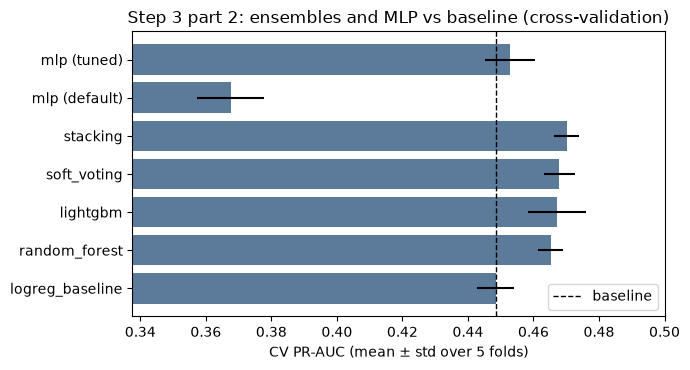

,cv_pr_auc_mean,cv_pr_auc_std,cv_roc_auc_mean,cv_roc_auc_std,train_pr_auc_mean,train_pr_auc_std,fit_time_s,gap_train_cv,gain_vs_baseline
model,,,,,,,,,
logreg_baseline,0.4484,0.0056,0.7886,0.0108,0.4558,0.0017,0.1972,0.0073,0.0000
random_forest,0.4653,0.0038,0.7987,0.0065,0.5717,0.0021,1.1642,0.1064,0.0168
lightgbm,0.4673,0.0089,0.8002,0.0063,0.5037,0.0018,0.3009,0.0364,0.0189
soft_voting,0.4679,0.0047,0.8000,0.0069,0.5202,0.0011,2.2996,0.0523,0.0194
stacking,0.4701,0.0038,0.8000,0.0064,0.5437,0.0014,14.1094,0.0736,0.0217
mlp (default),0.3676,0.0101,0.7341,0.0080,0.7410,0.0070,8.2953,0.3734,-0.0808
mlp (tuned),0.4529,0.0076,0.7863,0.0082,0.5345,0.0028,5.1013,0.0816,0.0045


In [9]:
cv_table = pd.DataFrame(rows).set_index("model")
cv_table["gain_vs_baseline"] = cv_table["cv_pr_auc_mean"] - cv_table.loc["logreg_baseline", "cv_pr_auc_mean"]
cv_table.to_csv(RESULTS / "cv_step3_part2.csv")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(cv_table.index, cv_table["cv_pr_auc_mean"], xerr=cv_table["cv_pr_auc_std"], color="#5c7a99")
ax.axvline(cv_table.loc["logreg_baseline", "cv_pr_auc_mean"], color="k", ls="--", lw=1, label="baseline")
ax.set_xlim(cv_table["cv_pr_auc_mean"].min() - 0.03, cv_table["cv_pr_auc_mean"].max() + 0.03)
ax.set_xlabel("CV PR-AUC (mean ± std over 5 folds)"); ax.legend(loc="lower right")
ax.set_title("Step 3 part 2: ensembles and MLP vs baseline (cross-validation)")
plt.tight_layout(); plt.savefig(FIGURES / "cv_step3_part2.png", dpi=150); plt.show()
cv_table

In [10]:
# one ensemble goes to notebook 04: the best one in CV (never chosen on the test set)
ensembles = ["stacking", "soft_voting"]
chosen = cv_table.loc[ensembles, "cv_pr_auc_mean"].idxmax()
for n in ensembles:
    f = RESULTS / f"best_params_{n}.json"
    if f.exists():
        f.unlink()
# no hyperparameter to tune for the ensemble itself: the file only tells notebook 04 to evaluate it
save_best_params(chosen, {})
print("ensemble sent to notebook 04:", chosen)

ensemble sent to notebook 04: stacking


## 5. Conclusion of step 3 (cross-validation)
| Version | Model | CV PR-AUC | Gain over the baseline |
|---|---|---|---|
| v0.1 | logistic regression (baseline) | 0.448 | |
| v0.2 | random forest / LightGBM | 0.465 / 0.467 | +0.017 / +0.019 |
| v0.3 | stacking (logistic regression + random forest + LightGBM) | 0.470 | +0.022 |
| v0.4 | multilayer perceptron | 0.453 | +0.005 (not more than the noise) |

* The ensemble is the best model in CV, but its gain over LightGBM alone is within the noise, for a cost 50 times
  higher.
* The model outside the course, the MLP, only matches the baseline after tuning.
* The stacking and the MLP are now registered in `src/models.py` (with `results/best_params_stacking.json` and
  `results/best_params_mlp.json`), so notebook 04 evaluates them on the test set, with the paired bootstrap
  against the baseline and on the temporal split. The final comparison is there.